# Do the results depend on how many binding calls are made?

The model returns a probability for every receptor x odorant pair. The paper turns them into calls
with a density fill (`Downstream_Analysis/scripts/calibration.py`): an isotonic map fitted on the
23,782 measured human pairs gives each untested cell a calibrated binding probability, their sum N is
the expected number of binders, and the N highest-scoring cells are called. Every result therefore
rests on N, which in turn rests on the measured binding rate (4.74%) and on the map.

This notebook redoes the paper's results with other calling rules:

- the density fill calling 0.5, 0.75, 1.5 and 2 times N cells, which asks whether the calibrated
  number matters;
- fixed probability cuts at 0.5 (the model's default), 0.7, 0.8 and 0.915 (the rate-matched cut of
  Extended Data Fig. 2), which drop the calibration altogether;
- the density fill without the measured values written over it (extant receptors only; the
  ancestral analyses never use them).

The first row of each table is the paper's rule and reproduces the paper's numbers; the notebook
checks that it rebuilds the paper's matrices exactly. Results that depend on the trajectory use the
calls without measurements at the tips, as the ancestral analyses do.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Supplementary_Material"))
import robustness_checks as rc
from robustness_checks import ac
from plotting_functions import custom_plots, FIGSIZE
import activation_figures as af
from activation_figures import CLASS_I_COLOUR, CLASS_II_COLOUR, INK, MUTED, save

plt.rcParams.update(custom_plots())
plt.rcParams.update(rc.TEXT_SIZES)
pd.set_option("display.max_columns", 50)

TABLES = Path("Tables")
FIGURES = Path("Figures")
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

In [2]:
RULES = [
    ("density fill (paper)", "rank", 1.0),
    ("density fill, 0.5 x N", "rank", 0.5),
    ("density fill, 0.75 x N", "rank", 0.75),
    ("density fill, 1.5 x N", "rank", 1.5),
    ("density fill, 2 x N", "rank", 2.0),
    ("p > 0.5 (model default)", "cut", 0.5),
    ("p > 0.7", "cut", 0.7),
    ("p > 0.8", "cut", 0.8),
    ("p > 0.915 (rate-matched)", "cut", 0.915),
]
extant = rc.load_extant_inputs()
data = extant.data
print(f"measured pairs: {len(data.measured)}, measured binding rate {data.measured_labels.mean():.4f}")

measured pairs: 23782, measured binding rate 0.0474


## Extant receptors

For each rule: the number of calls, tuning breadth by class (Fig. 2b), the chemistry of the odorants
only class I reads, both read, or only class II reads (Fig. 2c, 1/62 rule), and the six clusters
(Fig. 2e, Table 1). Measured values are written over the calls, as in the hybrid matrix.

In [3]:
rows = []
matrices = {}
for name, kind, value in RULES:
    if kind == "rank":
        calls = rc.rank_fill(data.scores, data.calibration_map, value, tested=data.tested)
    else:
        calls = rc.cut_fill(data.scores, value)
    matrix = rc.overlay(calls, data)
    if name == "density fill (paper)":
        assert (matrix == data.hybrid).all(), "the paper's rule must rebuild the hybrid matrix"
    matrices[name] = matrix
    rows.append(dict(rule=name, measurements_overlaid=True, **rc.extant_summary(matrix, extant)))

calls = rc.rank_fill(data.scores, data.calibration_map, 1.0)
rows.append(dict(rule="density fill, no measurements", measurements_overlaid=False,
                 **rc.extant_summary(calls.astype(int), extant)))
extant_by_rule = pd.DataFrame(rows)
extant_by_rule.to_csv(TABLES / "extant_by_calling_rule.csv", index=False)
extant_by_rule.round(3).set_index("rule").T

rule,density fill (paper),"density fill, 0.5 x N","density fill, 0.75 x N","density fill, 1.5 x N","density fill, 2 x N",p > 0.5 (model default),p > 0.7,p > 0.8,p > 0.915 (rate-matched),"density fill, no measurements"
measurements_overlaid,True,True,True,True,True,True,True,True,True,False
called_cells,8963,5046,7004,12880,16798,41325,27346,18760,6468,8963
odorants_with_a_call,687,641,664,719,735,752,752,739,661,668
median_ligands_class_I,8.5,3.0,7.0,15.5,22.0,65.0,39.5,26.0,6.0,8.5
median_ligands_class_II,4.0,1.0,2.0,9.0,14.0,54.0,29.0,16.0,2.0,3.0
breadth_P,0.019,0.0,0.002,0.038,0.051,0.074,0.091,0.049,0.002,0.04
n_class_I_only,111,110,110,111,110,33,93,101,115,85
pct_acid_class_I_only,47.748,38.182,43.636,53.153,54.545,6.061,44.086,57.426,41.739,55.294
pct_aromatic_class_I_only,16.216,23.636,20.909,15.315,13.636,15.152,11.828,13.861,20.87,18.824
n_shared,276,169,238,354,401,641,512,426,218,272


Under every rule but the most permissive one, the odorants only class I reads are the acid-rich
set (38-57% carboxylic acids) and those only class II reads carry almost none (0%), P < 10⁻¹⁰. At
p > 0.5 the model calls 13% of all cells and nearly every odorant is read by both classes, which leaves
too few class-specific odorants to compare. All six clusters carry an enriched odour descriptor under
every rule, and an acid-rich cluster with sour, acidic or cheesy descriptors appears under all but
one, although the cluster boundaries differ (adjusted Rand index 0.15-0.48 against the paper). The
breadth difference between the classes keeps its direction under every rule but is significant only
under some of them; it should be reported as a tendency.

### Do odorants with similar barcodes smell alike under every rule?

The paper reads the six clusters perceptually: odorants that activate similar receptor combinations
share odour descriptors. Two checks of that statement under each rule.

- Without clusters: over all pairs of odorants, the distance between receptor barcodes against the
  distance between odour-descriptor sets (Mantel test, Spearman, 999 permutations), plain and with
  structural distance held fixed. This is the test of `cluster_number`, section 5.
- With clusters: the six k-medoids clusters are rebuilt on each rule's matrix. How many carry a
  significantly enriched odour descriptor, and which odour themes of the paper they recover.

In [4]:
rows = []
for name, _, _ in RULES:
    test = rc.barcode_perception_test(matrices[name], extant)
    summary = extant_by_rule[extant_by_rule.rule == name].iloc[0]
    rows.append(dict(rule=name, **test, clusters_with_descriptor=summary.clusters_with_descriptor,
                     significant_enrichments=summary.significant_enrichments, themes=summary.themes))
perception_by_rule = pd.DataFrame(rows)
perception_by_rule.to_csv(TABLES / "perception_by_calling_rule.csv", index=False)
perception_by_rule.round(3).set_index("rule").T

rule,density fill (paper),"density fill, 0.5 x N","density fill, 0.75 x N","density fill, 1.5 x N","density fill, 2 x N",p > 0.5 (model default),p > 0.7,p > 0.8,p > 0.915 (rate-matched)
odorants,529,498,517,548,561,574,574,564,515
pairs,139656,123753,133386,149878,157080,164451,164451,158766,132355
rho_barcode_descriptor,0.14,0.162,0.144,0.144,0.139,0.113,0.126,0.134,0.152
P,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
rho_partial_on_structure,0.1,0.12,0.103,0.102,0.102,0.066,0.088,0.098,0.112
P_partial,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
rho_structure_descriptor,0.263,0.262,0.263,0.264,0.258,0.253,0.253,0.256,0.259
permutations,999,999,999,999,999,999,999,999,999
clusters_with_descriptor,6,6,6,6,6,6,6,6,6
significant_enrichments,30,27,26,38,41,38,27,38,27


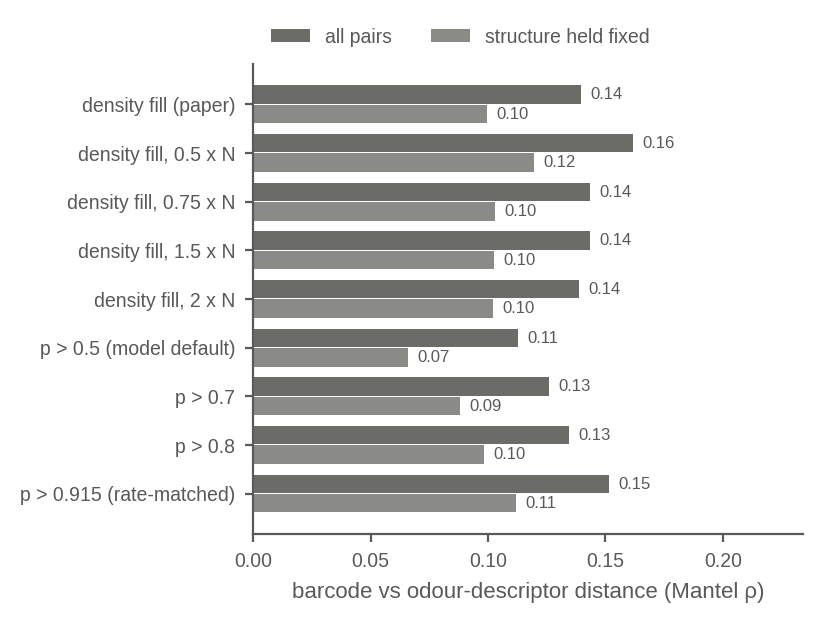

In [5]:
figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
positions = np.arange(len(perception_by_rule))
for offset, column, p_column, colour, label in [
        (-0.2, "rho_barcode_descriptor", "P", INK, "all pairs"),
        (0.2, "rho_partial_on_structure", "P_partial", MUTED, "structure held fixed")]:
    axis.barh(positions + offset, perception_by_rule[column], height=0.38, color=colour, label=label)
    for y, value, p in zip(positions + offset, perception_by_rule[column], perception_by_rule[p_column]):
        axis.text(value + 0.004, y, f"{value:.2f}" + ("" if p <= 0.001 else f" (P = {p:.3f})"),
                  va="center", fontsize=6)
axis.set_yticks(positions)
axis.set_yticklabels(perception_by_rule.rule, fontsize=7)
axis.invert_yaxis()
axis.set_xlim(0, perception_by_rule.rho_barcode_descriptor.max() * 1.45)
axis.set_xlabel("barcode vs odour-descriptor distance (Mantel ρ)")
axis.legend(frameon=False, fontsize=7, loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2)
save(figure, FIGURES / "barcode_perception_by_rule.svg", show=True)

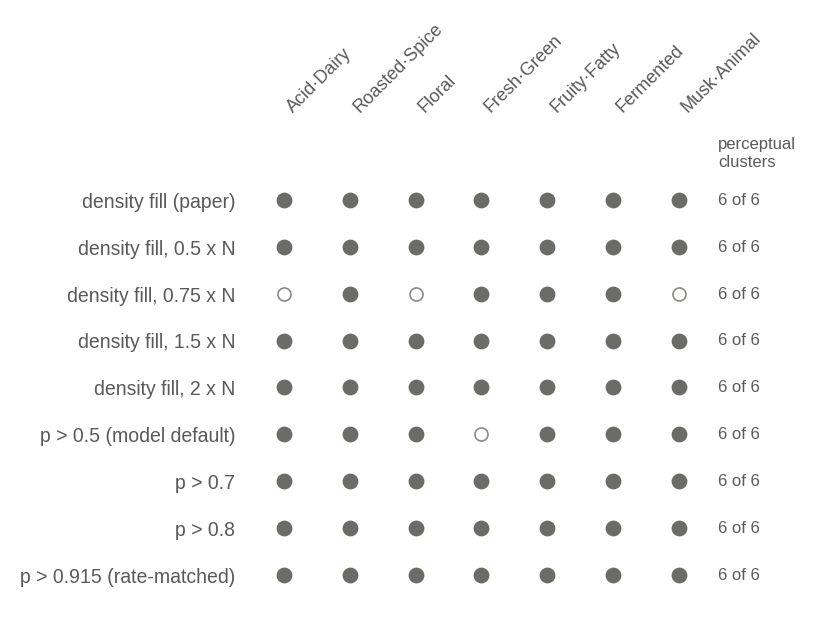

,rule,clusters_with_descriptor,themes
0,density fill (paper),6,Acid / Dairy / Cheese; Fermented / Solvent; Fl...
1,"density fill, 0.5 x N",6,Acid / Dairy / Cheese; Fermented / Solvent; Fl...
2,"density fill, 0.75 x N",6,Fermented / Solvent; Fresh / Green / Herbal; F...
3,"density fill, 1.5 x N",6,Acid / Dairy / Cheese; Fermented / Solvent; Fl...
4,"density fill, 2 x N",6,Acid / Dairy / Cheese; Fermented / Solvent; Fl...
5,p > 0.5 (model default),6,Acid / Dairy / Cheese; Fermented / Solvent; Fl...
6,p > 0.7,6,Acid / Dairy / Cheese; Fermented / Solvent; Fl...
7,p > 0.8,6,Acid / Dairy / Cheese; Fermented / Solvent; Fl...
8,p > 0.915 (rate-matched),6,Acid / Dairy / Cheese; Fermented / Solvent; Fl...


In [6]:
theme_names = [theme_name for _, theme_name, _ in ac.THEME_RULES]
found = np.array([[theme_name in str(themes).split("; ") for theme_name in theme_names]
                  for themes in perception_by_rule.themes])

figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
rule_index, theme_index = np.nonzero(found)
axis.scatter(theme_index, rule_index, s=22, color=INK, zorder=3)
rule_index, theme_index = np.nonzero(~found)
axis.scatter(theme_index, rule_index, s=22, facecolor="white", edgecolor=MUTED, linewidth=0.6, zorder=3)
for y, count in enumerate(perception_by_rule.clusters_with_descriptor):
    axis.text(len(theme_names) - 0.4, y, f"{count} of {ac.N_CLUSTERS}", va="center", fontsize=6)
axis.text(len(theme_names) - 0.4, -1, "perceptual\nclusters", va="center", fontsize=6)
axis.set_xticks(range(len(theme_names)))
axis.set_xticklabels([ac.SHORT_THEME.get(name, name) for name in theme_names], rotation=45, ha="left", fontsize=6.5)
axis.xaxis.tick_top()
axis.set_xlim(-0.6, len(theme_names) + 0.9)
axis.set_yticks(range(len(perception_by_rule)))
axis.set_yticklabels(perception_by_rule.rule, fontsize=7)
axis.set_ylim(len(perception_by_rule) - 0.4, -1.6)
axis.tick_params(length=0)
for side in axis.spines.values():
    side.set_visible(False)
save(figure, FIGURES / "themes_by_rule.svg", show=True)
perception_by_rule[["rule", "clusters_with_descriptor", "themes"]]

Under every rule, odorants with more similar barcodes have more similar odour descriptors (Mantel
ρ 0.11-0.16, P = 0.001), also with structural similarity held fixed (0.07-0.12). At the permissive cuts
p > 0.5, 0.7 and 0.8, which call 4.6, 3.1 and 2.1 times as many pairs as the density fill, ρ is 0.11,
0.13 and 0.13, against 0.14 for the paper's rule. The six clusters rebuilt under each rule all carry an
enriched descriptor and recover the same odour themes (all seven under seven of the rules, six at
p > 0.5 and four at 0.75 x N). Which odorant falls in which cluster changes with the rule; that
similar barcodes go with similar odours does not.

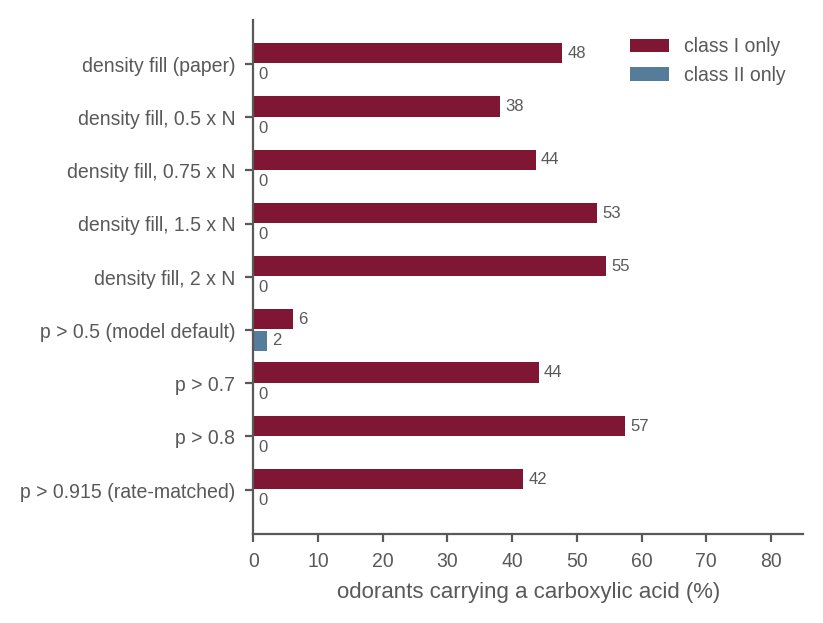

In [7]:
figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
shown = extant_by_rule[extant_by_rule.measurements_overlaid]
positions = np.arange(len(shown))
for offset, column, colour, label in [(-0.2, "pct_acid_class_I_only", CLASS_I_COLOUR, "class I only"),
                                      (0.2, "pct_acid_class_II_only", CLASS_II_COLOUR, "class II only")]:
    axis.barh(positions + offset, shown[column], height=0.38, color=colour, label=label)
    for y, value in zip(positions + offset, shown[column]):
        axis.text(value + 0.8, y, f"{value:.0f}", va="center", fontsize=6)
axis.set_yticks(positions)
axis.set_yticklabels(shown.rule, fontsize=7)
axis.invert_yaxis()
axis.set_xlim(0, 85)
axis.set_xlabel("odorants carrying a carboxylic acid (%)")
axis.legend(frameon=False, fontsize=7, loc="upper right")
save(figure, FIGURES / "acid_by_class_and_rule.svg", show=True)

### The activation matrix and its descriptors at the fixed cuts

The matrix of Fig. 2a and the odour-descriptor enrichment of Fig. 2e, drawn again for the cuts at
0.5, 0.7 and 0.8. The six clusters are rebuilt on each matrix, as in the table above.

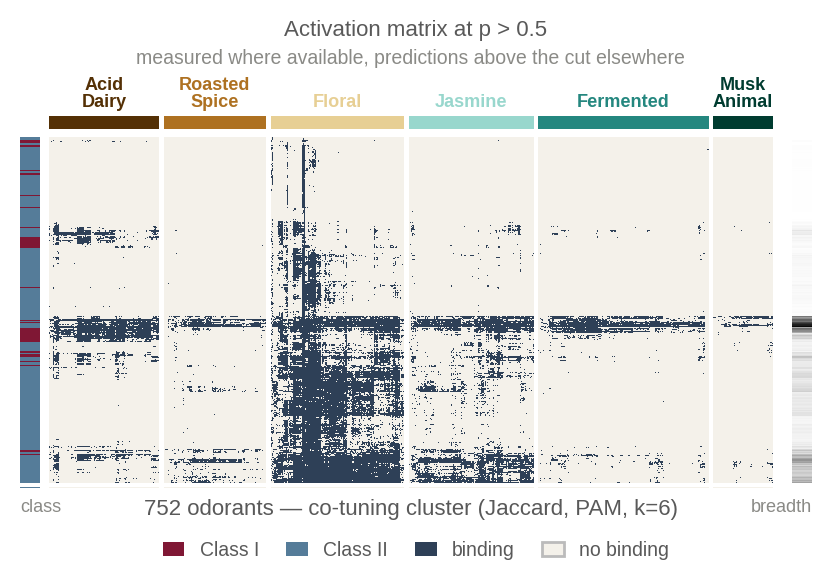

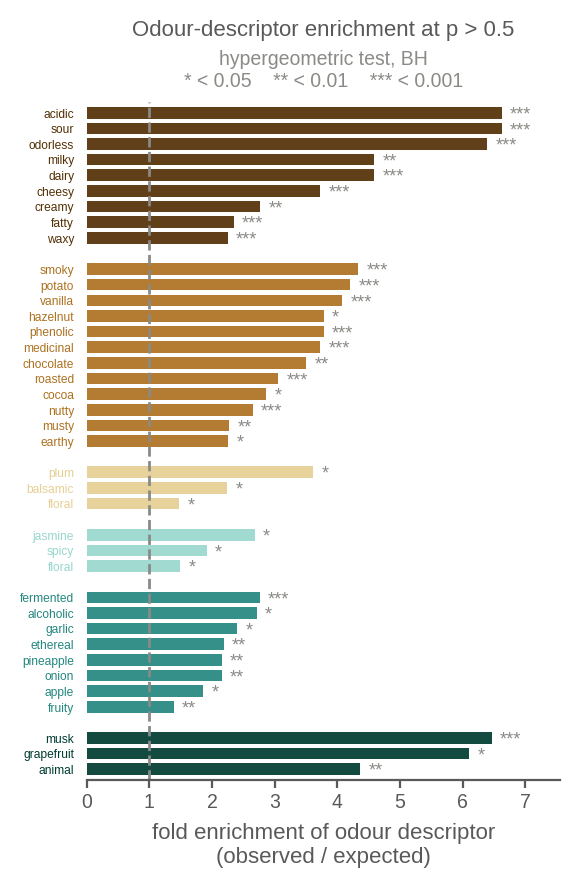

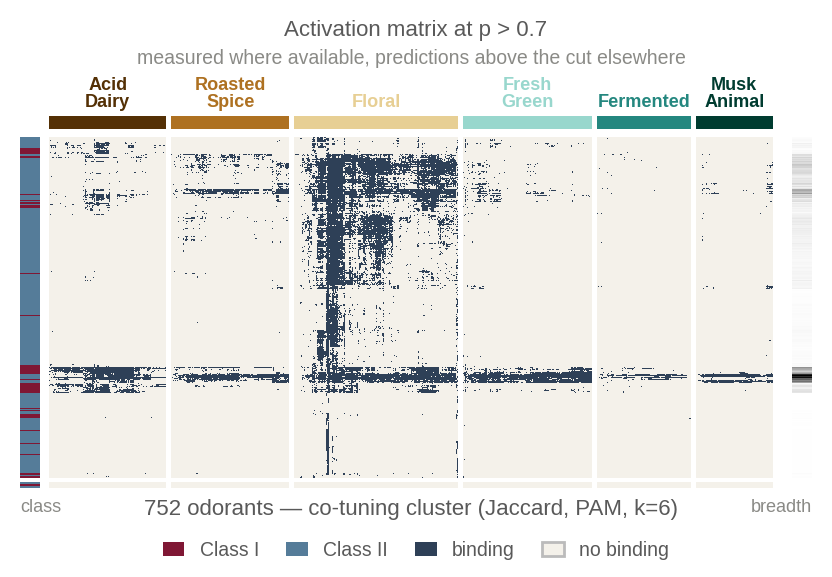

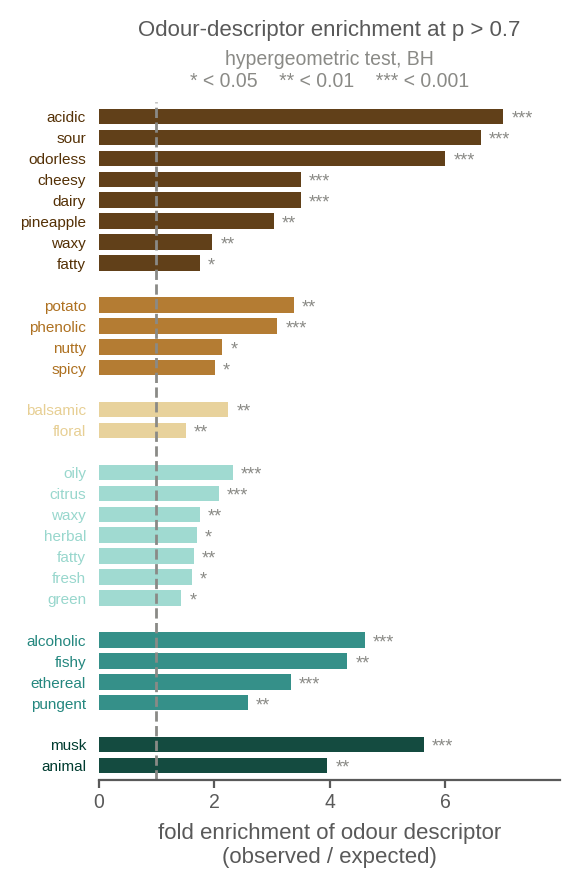

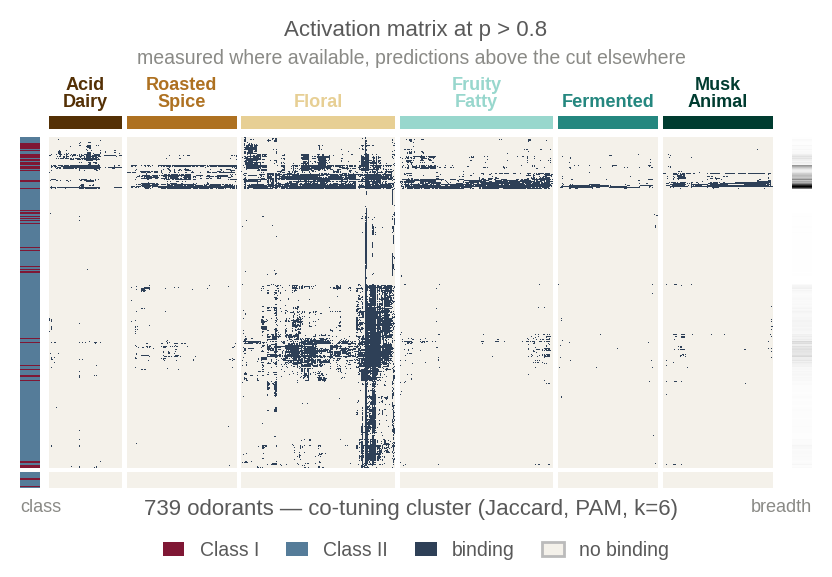

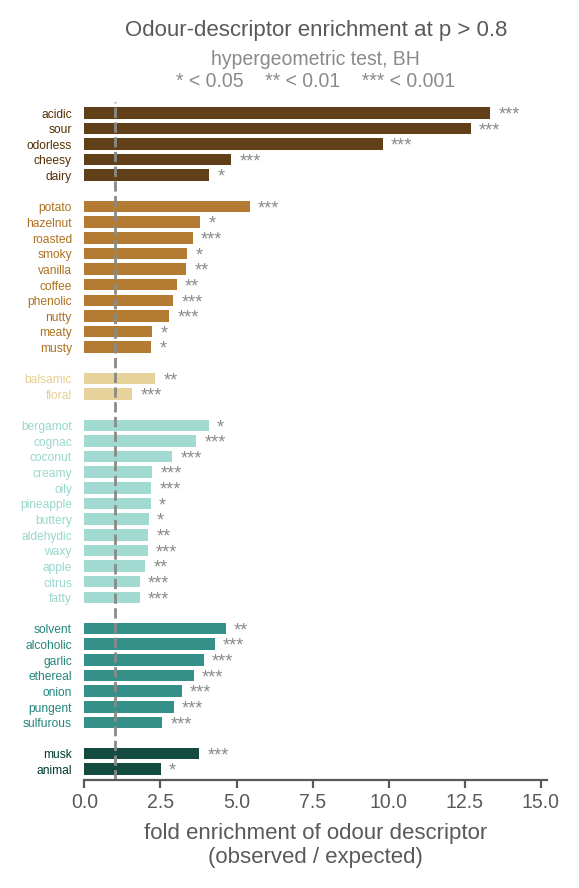

,cut,called_pairs,odorants_with_a_call,orphan_receptors,significant_enrichments
0,p > 0.5,41325,752,1,38
1,p > 0.7,27346,752,8,27
2,p > 0.8,18760,739,20,38


In [8]:
fixed_cut_rows = []
for name, cut in [("p > 0.5 (model default)", 0.5), ("p > 0.7", 0.7), ("p > 0.8", 0.8)]:
    clustered_ids, clustered_matrix, labels = ac.cluster_odorants(matrices[name], data.odorant_ids)
    enrichment = ac.tag_enrichment(clustered_ids, labels, extant.tags_by_odorant)
    info, display_order = ac.name_clusters(enrichment, labels)
    significant = ac.significant_enrichment(enrichment)
    af.activation_heatmap(clustered_ids, clustered_matrix, labels, info, display_order, data.receptor_ids,
                          extant.class_of, f"Activation matrix at p > {cut}",
                          "measured where available, predictions above the cut elsewhere",
                          FIGURES / f"activation_matrix_p_{cut}.svg", row_order="cotuning", show=True)
    af.enrichment_bars(significant, info, display_order, f"Odour-descriptor enrichment at p > {cut}",
                       FIGURES / f"cluster_tag_enrichment_p_{cut}.svg", show=True)
    fixed_cut_rows.append({"cut": f"p > {cut}", "called_pairs": int(np.asarray(clustered_matrix).sum()),
                           "odorants_with_a_call": len(clustered_ids),
                           "orphan_receptors": int((np.asarray(clustered_matrix).sum(axis=1) == 0).sum()),
                           "significant_enrichments": len(significant)})
fixed_cuts = pd.DataFrame(fixed_cut_rows)
fixed_cuts.to_csv(TABLES / "matrix_at_fixed_cuts.csv", index=False)
fixed_cuts

## Ancestral receptors

The same rules applied to the ancestral and extant prediction matrices together, each filled from its
own scores with the one calibration map, as in the paper. For each rule: the repertoires of nodes 0, 1,
2 and 5, what the two class ancestors kept, lost and gained (Fig. 3d), the chemistry gained along the
two founding duplications (Fisher's exact test against the rest of the panel), the
combinatorial-coding trajectory (Fig. 3h), the decay of parent-child similarity (Fig. 3f) and the
breadth of ancestors against extant receptors (Extended Data Fig. 6a).

In [9]:
ancestral = rc.load_ancestral_inputs()
rows = []
for name, kind, value in RULES:
    if kind == "rank":
        ancestral_calls = rc.rank_fill(ancestral.ancestral_scores.values, ancestral.calibration_map, value)
        extant_calls = rc.rank_fill(ancestral.extant_scores.values, ancestral.calibration_map, value)
    else:
        ancestral_calls = rc.cut_fill(ancestral.ancestral_scores.values, value)
        extant_calls = rc.cut_fill(ancestral.extant_scores.values, value)
    binary = rc.ancestral_calls(ancestral_calls, extant_calls, ancestral)
    if name == "density fill (paper)":
        assert binary.equals(ancestral.paper_binary), "the paper's rule must rebuild the ancestral calls"
    rows.append(dict(rule=name, **rc.ancestral_summary(binary, ancestral)))
ancestral_by_rule = pd.DataFrame(rows)
ancestral_by_rule.to_csv(TABLES / "ancestral_by_calling_rule.csv", index=False)
ancestral_by_rule.round(4).set_index("rule").T

rule,density fill (paper),"density fill, 0.5 x N","density fill, 0.75 x N","density fill, 1.5 x N","density fill, 2 x N",p > 0.5 (model default),p > 0.7,p > 0.8,p > 0.915 (rate-matched)
node_0_ligands,21,3,12,38,51,177,119,67,5
node_1_ligands,21,8,13,29,42,130,78,51,9
node_2_ligands,8,1,2,22,30,113,61,36,1
node_5_ligands,27,2,17,41,54,130,93,64,3
node_0_to_1_kept,4,1,3,6,11,41,22,15,2
node_0_to_1_lost,17,2,9,32,40,136,97,52,3
node_0_to_1_gained,17,7,10,23,31,89,56,36,7
node_0_to_2_kept,7,1,2,20,28,113,60,34,1
node_0_to_2_lost,14,2,10,18,23,64,59,33,4
node_0_to_2_gained,1,0,0,2,2,0,1,2,0


Along the class I branch the gained odorants are enriched for carboxylic acids under every rule.
Along the branch to node 5 they are enriched for aromatic rings under every rule that leaves that
branch more than two gains; under the two sparsest rules (0.5 x N and p > 0.915) node 5 gains one or
two odorants, all aromatic. The class I ancestor replaces most of the ancestral repertoire and the
class II ancestor gains almost nothing under every rule. Odorants read by two receptors are present
at the first duplication under every rule, combinatorial odorants become the majority as lineages are
added, and the functional half-life stays between 0.13 and 0.18 substitutions per site except at
0.5 x N, where repertoires are so small that many branches have none. Ancestors are broader than
extant receptors under every rule, as expected of reconstructed sequences.

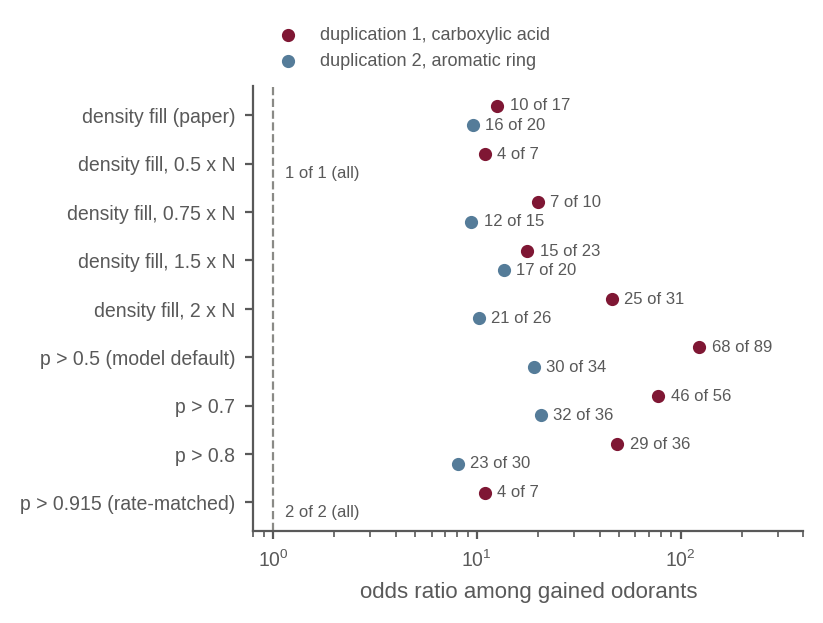

In [10]:
figure, axis = plt.subplots(figsize=FIGSIZE, layout="constrained")
positions = np.arange(len(ancestral_by_rule))
for offset, column, colour, label in [(-0.2, "duplication_1_acid_odds_ratio", CLASS_I_COLOUR,
                                       "duplication 1, carboxylic acid"),
                                      (0.2, "duplication_2_aromatic_odds_ratio", CLASS_II_COLOUR,
                                       "duplication 2, aromatic ring")]:
    values = ancestral_by_rule[column].replace(np.inf, np.nan)
    axis.scatter(values, positions + offset, color=colour, s=14, label=label, zorder=3)
    gains = ancestral_by_rule[column.replace("odds_ratio", "gained")]
    for y, value, gained in zip(positions + offset, values, gains):
        text = f"{gained}" if np.isfinite(value) else f"{gained} (all)"
        axis.text((value if np.isfinite(value) else 1.0) * 1.15, y, text, va="center", fontsize=6)
axis.axvline(1, color=MUTED, lw=0.8, ls="--")
axis.set_xscale("log")
axis.set_ylim(-0.6, len(ancestral_by_rule) - 0.4)
axis.set_yticks(positions)
axis.set_yticklabels(ancestral_by_rule.rule, fontsize=7)
axis.invert_yaxis()
axis.set_xlim(0.8, 400)
axis.set_xlabel("odds ratio among gained odorants")
axis.legend(frameon=False, fontsize=6.5, loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=1)
save(figure, FIGURES / "founding_duplications_by_rule.svg", show=True)